# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [5]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [6]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [7]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"

# TODO: carga el archivo en un DataFrame llamado df
df = pd.read_csv(DATA_PATH)


In [9]:
# TODO: reporta forma, tipos, nulos, duplicados y distribución de target

print("--- Forma del DataFrame ---")
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}\n")

print("--- Tipos de datos e Información general ---")
print(df.info())

print("\n--- Valores nulos por columna ---")
print(df.isnull().sum())

print(f"\n--- Duplicados totales ---")
print(f"Número de filas duplicadas: {df.duplicated().sum()}")

if "target" in df.columns:
    print("\n--- Distribución de la variable objetivo (target) ---")
    print(df["target"].value_counts(normalize=True))


--- Forma del DataFrame ---
Filas: 178, Columnas: 14

--- Tipos de datos e Información general ---
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 n

**Conclusión de calidad:**

El dataset está intacto. Son 178 filas y 14 columnas sin un solo valor nulo, así que no hay que perder tiempo imputando datos. Los tipos están perfectos (float64 para las variables y int64 para el target) y la variable objetivo está bastante nivelada (40% clase 1, 33% clase 0 y 27% clase 2).

En resumen: los datos vienen limpios desde la fuente, no hace falta borrar nada ni meterle serrucho antes de hacer el split. Pasamos directo a dividir en train y test.

## 2. Split train/test

In [11]:
# TODO: crea train_df (80 %) y test_df (20 %)
# Requisitos: stratify=df["target"] y random_state=RANDOM_STATE

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["target"],
    random_state=RANDOM_STATE
)

#raise NotImplementedError("TODO 3: crea el split")

In [12]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

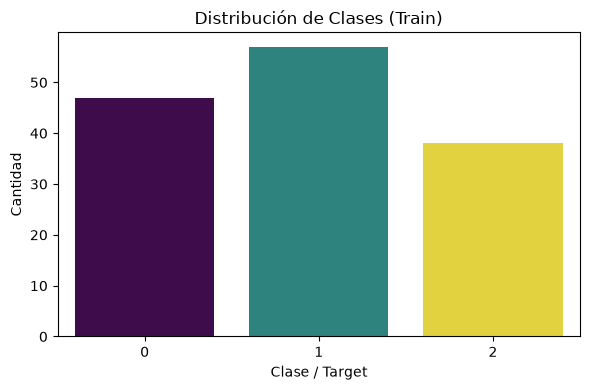

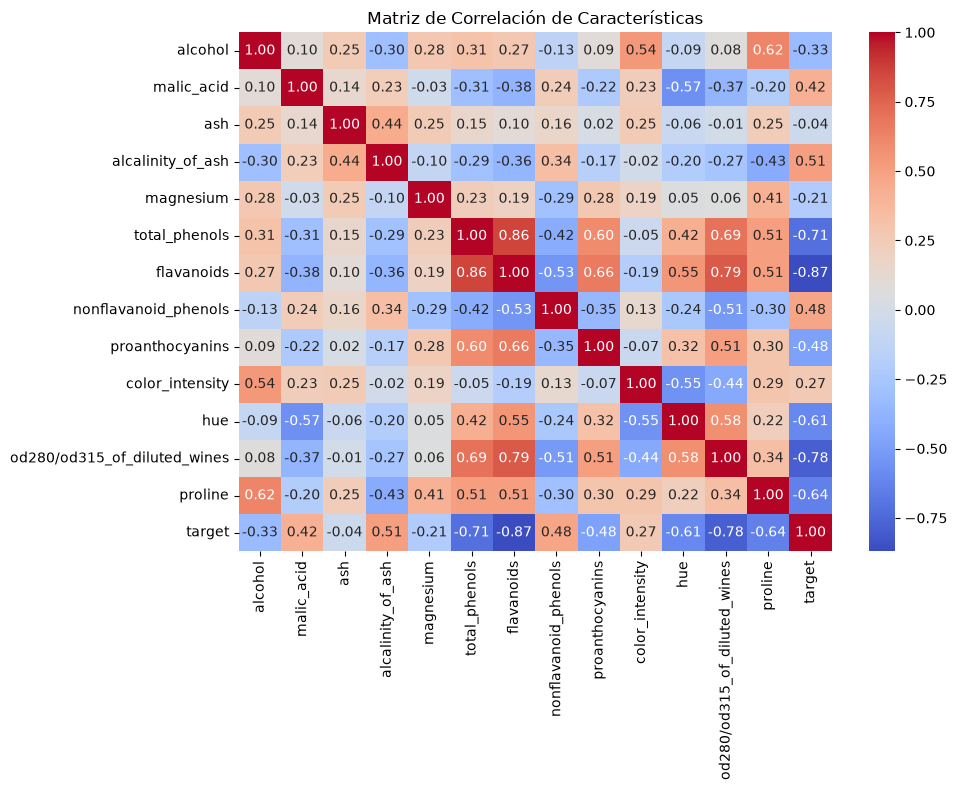

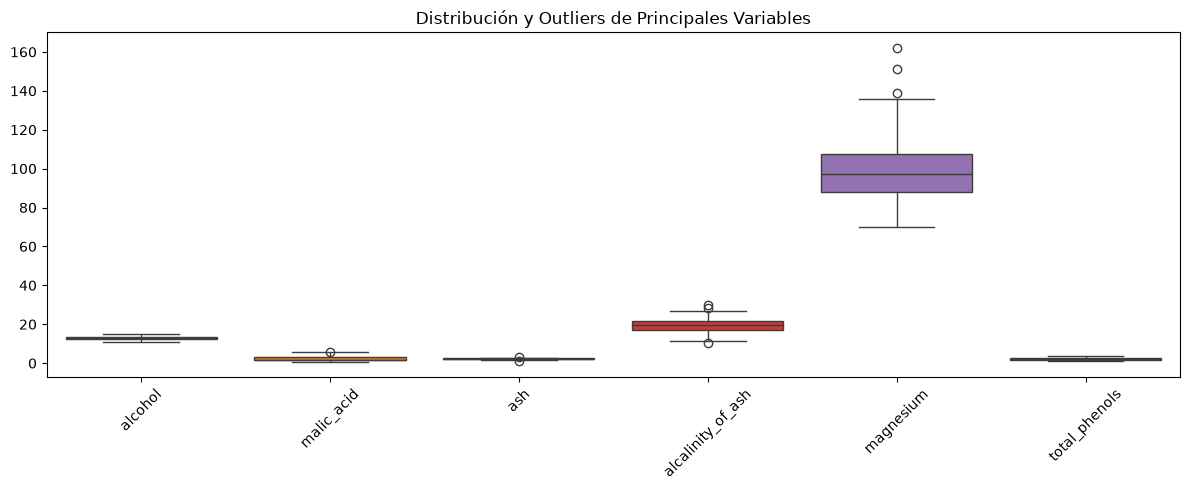

In [14]:
# TODO: crea al menos tres visualizaciones usando solamente train_df

# 1. Distribución de clases
plt.figure(figsize=(6, 4))
sns.countplot(data=train_df, x="target", hue="target", palette="viridis", legend=False)
plt.title("Distribución de Clases (Train)")
plt.xlabel("Clase / Target")
plt.ylabel("Cantidad")
plt.tight_layout()
plt.show()

# 2. Matriz de correlación
plt.figure(figsize=(10, 8))
corr = train_df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Matriz de Correlación de Características")
plt.tight_layout()
plt.show()

# 3. Boxplot para analizar dispersión y outliers en variables clave
numeric_cols = [col for col in train_df.columns if col != "target"]
plt.figure(figsize=(12, 5))
sns.boxplot(data=train_df[numeric_cols[:6]])  # Muestra las primeras 6 variables numéricas
plt.title("Distribución y Outliers de Principales Variables")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#raise NotImplementedError("TODO 4: realiza el EDA")

**Hallazgos:**

1.
2.
3.

## 4. Persistencia de datos y contrato

In [16]:
# TODO: reinicia los índices y guarda train.csv y test.csv sin el índice

# 1. Reiniciar índices y guardar datasets en formato CSV
train_df_reset = train_df.reset_index(drop=True)
test_df_reset = test_df.reset_index(drop=True)

train_df_reset.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df_reset.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

# 2. Construir el contrato de datos en JSON
feature_names = [col for col in train_df_reset.columns if col != "target"]

data_contract = {
    "target": "target",
    "features": feature_names,
    "random_state": RANDOM_STATE,
    "test_size": 0.2,
    "n_train_samples": len(train_df_reset),
    "n_test_samples": len(test_df_reset)
}

# 3. Guardar el contrato
with open(ARTIFACTS_DIR / "data_contract.json", "w", encoding="utf-8") as f:
    json.dump(data_contract, f, indent=4)

# raise NotImplementedError("TODO 5: guarda las salidas")

In [17]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [V] Cargué el CSV desde `data`.
- [V] Revisé calidad y distribución de la clase.
- [V] Realicé un split estratificado.
- [V] No exploré el conjunto de test.
- [V] Guardé los tres artefactos requeridos.